<a href="https://colab.research.google.com/github/williamryanmckee-nwa/Deep-Learning/blob/main/boat_type_classification_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Boat Type Classification Using Python and CNN

This beginner-friendly notebook builds an image-classification model for the boat image dataset.

**Goal:** Predict the boat category from an image.

**Workflow**
1. Extract the dataset ZIP file.
2. Locate the class folders.
3. Load and visualize images.
4. Split data into training and testing sets.
5. Build and train a simple CNN.
6. Evaluate the model and make a prediction.

> **Note:** This is an image classification task, so a Convolutional Neural Network (CNN) is more suitable than a standard decision tree on tabular CSV data. Model accuracy depends on the dataset and training run.

## 1. Install and import libraries

If TensorFlow is not installed in your environment, uncomment and run the installation command below.

In [35]:
# %pip install tensorflow matplotlib scikit-learn

import os
import zipfile
import pathlib
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 2. Extract the dataset ZIP file

The notebook expects `boat_type_classification_dataset.zip` to be in the same directory as this notebook. If it is elsewhere, update `ZIP_PATH`.

The extraction code safely handles the common case where the ZIP contains a single top-level folder.

In [36]:
ZIP_PATH = "boat_type_classification_dataset.zip"
EXTRACT_DIR = "boat_dataset"

if not os.path.exists(ZIP_PATH):
    # In the ChatGPT execution environment, the uploaded file may be here:
    candidate = ""
    if os.path.exists(candidate):
        ZIP_PATH = candidate
    else:
        raise FileNotFoundError(
            f"Could not find {ZIP_PATH}. Place the ZIP beside this notebook "
            "or update ZIP_PATH to its location."
        )

os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    zf.extractall(EXTRACT_DIR)

print("Extracted to:", os.path.abspath(EXTRACT_DIR))

Extracted to: /content/boat_dataset


In [37]:
import os

zip_path = "boat_type_classification_dataset.zip"
if os.path.exists(zip_path):
    file_size_bytes = os.path.getsize(zip_path)
    file_size_mb = file_size_bytes / (1024 * 1024)
    print(f"File: {zip_path}")
    print(f"Size: {file_size_bytes} bytes ({file_size_mb:.2f} MB)")
else:
    print(f"File not found: {zip_path}")

File: boat_type_classification_dataset.zip
Size: 150395635 bytes (143.43 MB)


## 3. Find the folder containing class subfolders

Each class folder should contain images for one boat category. This cell searches for the directory that contains the largest number of immediate subdirectories, which helps accommodate different ZIP layouts.

In [38]:
root = pathlib.Path(EXTRACT_DIR)
candidate_dirs = [root] + [p for p in root.rglob("*") if p.is_dir()]

def image_count(folder):
    extensions = {".jpg", ".jpeg", ".png", ".bmp", ".gif"}
    return sum(1 for p in folder.rglob("*") if p.is_file() and p.suffix.lower() in extensions)

# Candidate directories must have at least two child directories.
folder_candidates = [
    p for p in candidate_dirs
    if sum(1 for child in p.iterdir() if child.is_dir()) >= 2
]

if not folder_candidates:
    raise FileNotFoundError(
        "Could not identify class folders. Inspect the extracted directory and set DATA_DIR manually."
    )

DATA_DIR = str(max(folder_candidates, key=lambda p: sum(1 for child in p.iterdir() if child.is_dir())))
print("Detected dataset directory:", DATA_DIR)
print("Class folders:")
for child in sorted(pathlib.Path(DATA_DIR).iterdir()):
    if child.is_dir():
        print(" -", child.name, f"({image_count(child)} images)")

Detected dataset directory: boat_dataset/boat_type_classification_dataset
Class folders:
 - buoy (53 images)
 - cruise_ship (191 images)
 - ferry_boat (63 images)
 - freight_boat (23 images)
 - gondola (193 images)
 - inflatable_boat (16 images)
 - kayak (203 images)
 - paper_boat (31 images)
 - sailboat (389 images)


## 4. Load training and testing images

Images are resized to 128 × 128 pixels. The dataset is split into 80% training and 20% testing images using a fixed seed for reproducibility.

This simple split is not stratified. For strongly imbalanced datasets, review per-class metrics in addition to overall accuracy.

In [39]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

class_names = train_ds.class_names
num_classes = len(class_names)

print("Class names:", class_names)
print("Number of classes:", num_classes)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000, seed=SEED).prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size=AUTOTUNE)

Found 1162 files belonging to 9 classes.
Using 930 files for training.
Found 1162 files belonging to 9 classes.
Using 232 files for validation.
Class names: ['buoy', 'cruise_ship', 'ferry_boat', 'freight_boat', 'gondola', 'inflatable_boat', 'kayak', 'paper_boat', 'sailboat']
Number of classes: 9


## 5. Visualize sample images

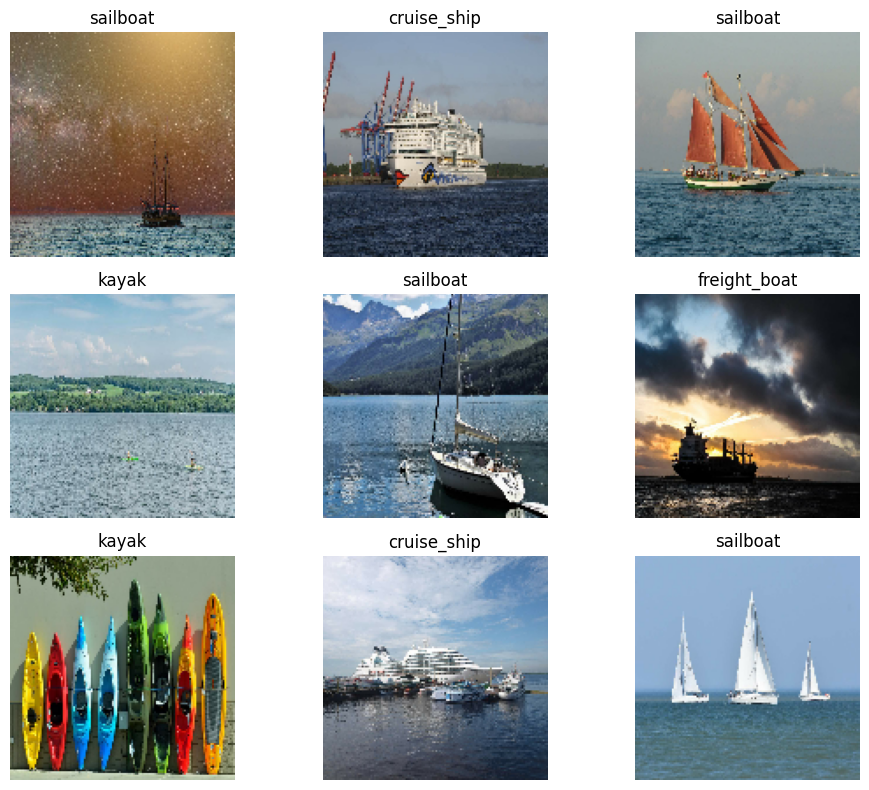

In [40]:
plt.figure(figsize=(10, 8))
for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i].numpy())])
        plt.axis("off")
plt.tight_layout()
plt.show()

## 6. Build the CNN model

- **Rescaling:** changes pixel values from 0–255 to 0–1.
- **Conv2D:** learns visual features such as edges and shapes.
- **MaxPooling2D:** reduces spatial dimensions.
- **Flatten:** converts feature maps into a vector.
- **Dense:** learns combinations of extracted features.
- **Softmax:** outputs a probability for each class.

In [41]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),
    tf.keras.layers.Rescaling(1.0 / 255),

    tf.keras.layers.Conv2D(16, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_5 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 126, 126, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 63, 63, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 61, 61, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 28800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │     1,843,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 9)              │           585 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,848,937 (7.05 MB)

 Trainable params: 1,848,937 (7.05 MB)

 Non-trainable params: 0 (0.00 B)

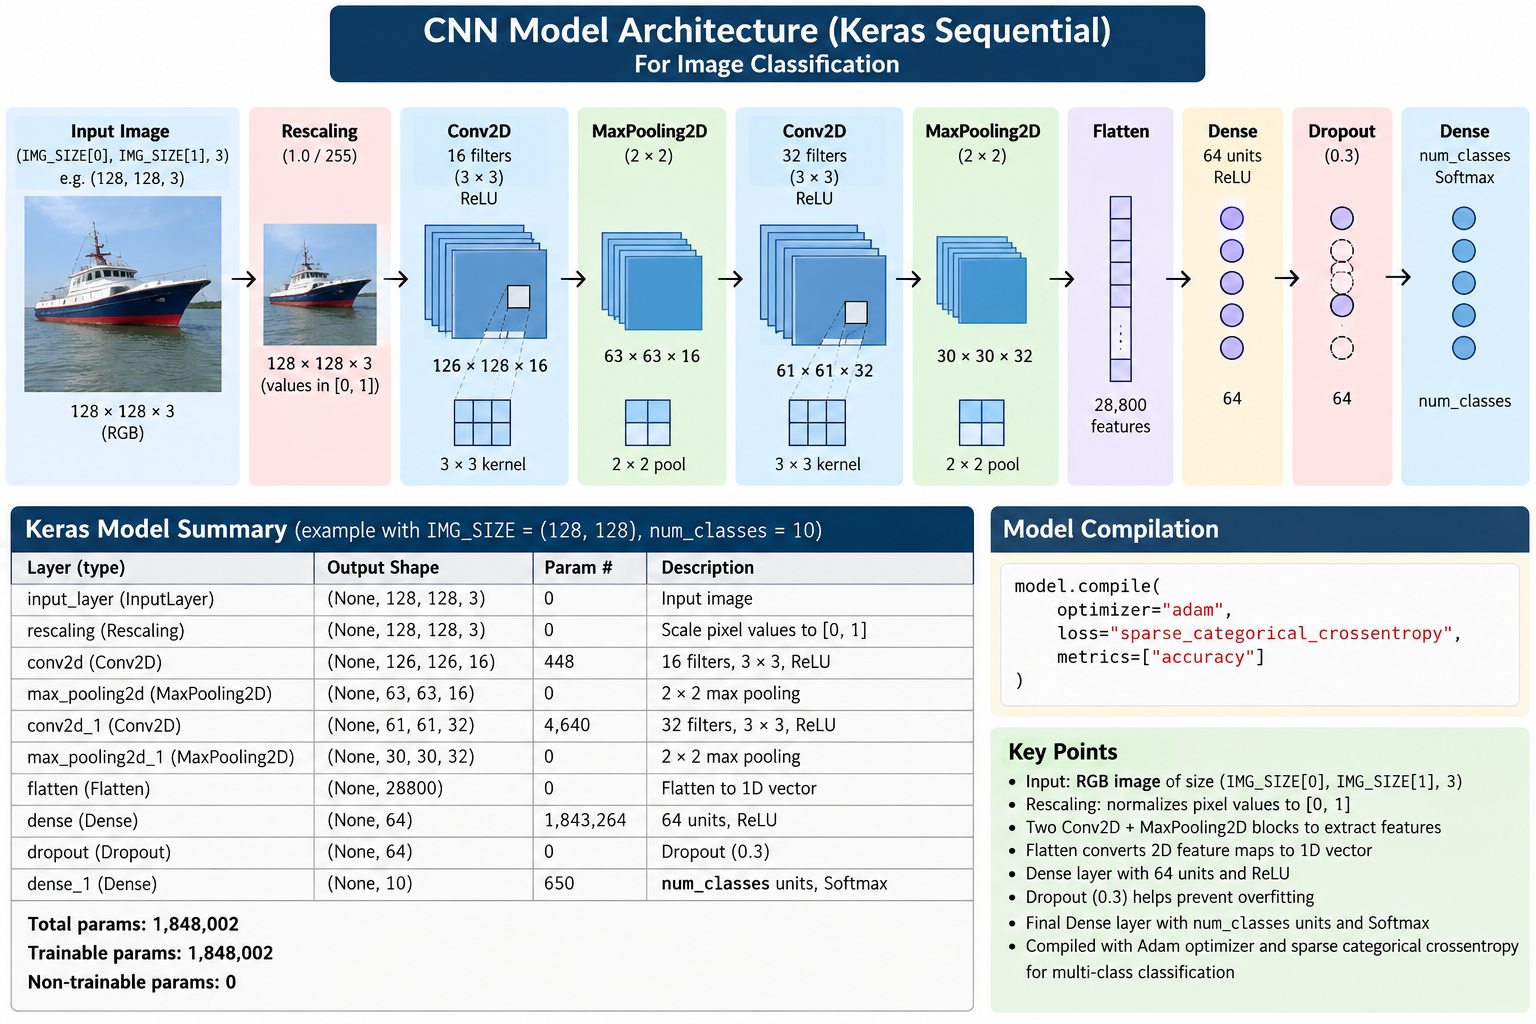

## 7. Train the model

The default is 10 epochs. Increase this number if you want to experiment, while checking for overfitting.

In [42]:
EPOCHS = 10

history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=EPOCHS
)

Epoch 1/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 15s 453ms/step - accuracy: 0.2484 - loss: 2.1043 - val_accuracy: 0.3750 - val_loss: 1.7116
Epoch 2/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 12s 398ms/step - accuracy: 0.3237 - loss: 1.7998 - val_accuracy: 0.4655 - val_loss: 1.6874
Epoch 3/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 11s 371ms/step - accuracy: 0.4237 - loss: 1.6460 - val_accuracy: 0.5560 - val_loss: 1.4912
Epoch 4/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 11s 367ms/step - accuracy: 0.4796 - loss: 1.5243 - val_accuracy: 0.5216 - val_loss: 1.4536
Epoch 5/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 21s 391ms/step - accuracy: 0.5548 - loss: 1.3961 - val_accuracy: 0.5000 - val_loss: 1.4097
Epoch 6/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 20s 385ms/step - accuracy: 0.5828 - loss: 1.2649 - val_accuracy: 0.5517 - val_loss: 1.3550
Epoch 7/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 11s 365ms/step - accuracy: 0.6108 - loss: 1.1618 - val_accuracy: 0.5647 - val_loss: 1.3403
Epoch 8/10
30/30 ━━━━━━━━━━━━━━━━━━━━ 22s 410ms/step - accuracy: 0.6624 - loss: 1.0399 - val_accu

## 8. Evaluate the model

In [43]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.2%}")

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 86ms/step - accuracy: 0.5172 - loss: 1.3912
Test loss: 1.3912
Test accuracy: 51.72%


## 9. Plot training and validation accuracy and loss

A large gap between training and validation accuracy can indicate overfitting.

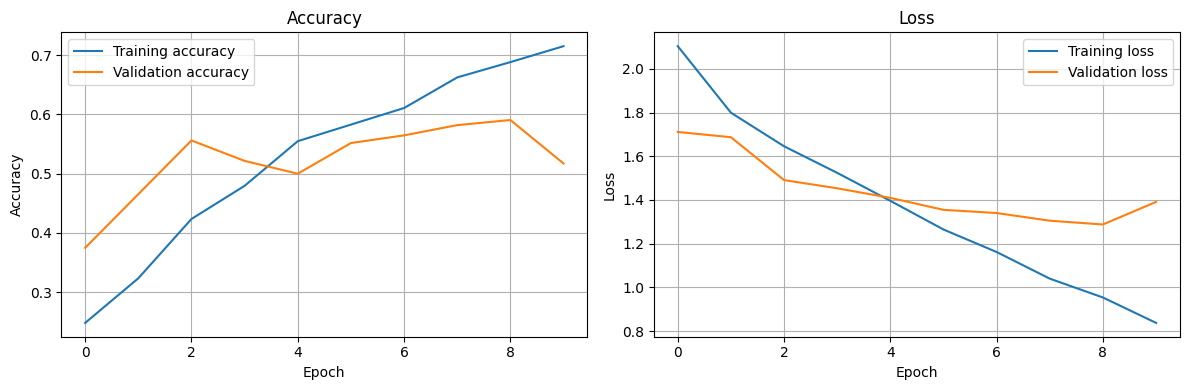

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="Training accuracy")
axes[0].plot(history.history["val_accuracy"], label="Validation accuracy")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(history.history["loss"], label="Training loss")
axes[1].plot(history.history["val_loss"], label="Validation loss")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

## 10. Confusion matrix and per-class metrics

The confusion matrix shows which classes are being confused with each other. Precision, recall, and F1-score help evaluate performance for each class, which is important when classes are imbalanced.

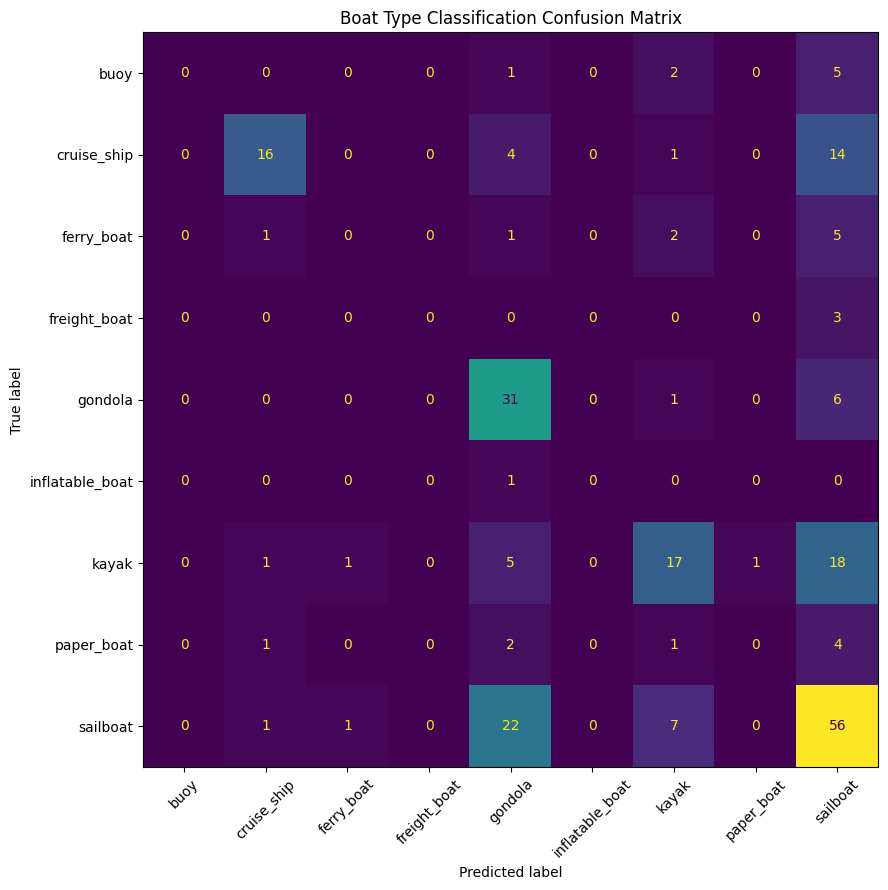

                 precision    recall  f1-score   support

           buoy       0.00      0.00      0.00         8
    cruise_ship       0.80      0.46      0.58        35
     ferry_boat       0.00      0.00      0.00         9
   freight_boat       0.00      0.00      0.00         3
        gondola       0.46      0.82      0.59        38
inflatable_boat       0.00      0.00      0.00         1
          kayak       0.55      0.40      0.46        43
     paper_boat       0.00      0.00      0.00         8
       sailboat       0.50      0.64      0.57        87

       accuracy                           0.52       232
      macro avg       0.26      0.26      0.24       232
   weighted avg       0.49      0.52      0.48       232



In [45]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

y_true = []
y_pred = []

for images, labels in test_ds:
    probabilities = model.predict(images, verbose=0)
    predictions = np.argmax(probabilities, axis=1)
    y_true.extend(labels.numpy().astype(int))
    y_pred.extend(predictions.astype(int))

cm = confusion_matrix(y_true, y_pred, labels=list(range(num_classes)))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

fig, ax = plt.subplots(figsize=(11, 9))
disp.plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.title("Boat Type Classification Confusion Matrix")
plt.tight_layout()
plt.show()

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(num_classes)),
    target_names=class_names,
    zero_division=0
))

## 11. Predict the class of a new image

Change `IMAGE_PATH` to point to an image you want to classify. The image can be outside the training dataset for a more meaningful demonstration.

In [46]:
IMAGE_PATH = ""  # Example: "my_boat_photo.jpg"

if IMAGE_PATH and os.path.exists(IMAGE_PATH):
    image = tf.keras.utils.load_img(IMAGE_PATH, target_size=IMG_SIZE)
    image_array = tf.keras.utils.img_to_array(image)
    image_batch = np.expand_dims(image_array, axis=0)

    probabilities = model.predict(image_batch, verbose=0)[0]
    predicted_index = int(np.argmax(probabilities))

    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.title(
        f"Predicted: {class_names[predicted_index]} "
        f"({probabilities[predicted_index]:.1%})"
    )
    plt.axis("off")
    plt.show()

    print("Predicted class:", class_names[predicted_index])
    print("Confidence:", f"{probabilities[predicted_index]:.2%}")
else:
    print("Set IMAGE_PATH to an image file to run a single-image prediction.")

Set IMAGE_PATH to an image file to run a single-image prediction.


## 12. Save the trained model

Run this cell after training to save the model for later use.

In [47]:
model.save("boat_type_classifier.keras")
print("Saved model to boat_type_classifier.keras")

Saved model to boat_type_classifier.keras


## Summary

This notebook demonstrates a complete introductory image-classification workflow:
- loading image data from class folders,
- splitting the dataset,
- building and training a CNN,
- evaluating accuracy and per-class performance,
- predicting the category of a new image, and
- saving the trained model.

### Exercises
1. Train for 5, 10, and 20 epochs and compare results.
2. Increase the convolution filters from 16/32 to 32/64.
3. Compare performance with and without dropout.
4. Explain why accuracy alone may be misleading when the classes are imbalanced.